In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the dataset
df = pd.read_csv("online_shoppers_intention.csv")

# Display the first five records
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the available columns
print("\nDataset columns:")
print(df.columns.tolist())

Dataset shape: (12330, 18)

Dataset columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


In [5]:
# Check the data types of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [6]:
# Check missing values in each column
print(df.isnull().sum())

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [7]:
# Check the number of duplicate rows
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 125


In [8]:
# Check how many sessions resulted in a purchase
print(df["Revenue"].value_counts())

# Display the percentage of each class
print("\nTarget distribution (%):")
print(df["Revenue"].value_counts(normalize=True) * 100)

Revenue
False    10422
True      1908
Name: count, dtype: int64

Target distribution (%):
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


In [9]:
# Remove duplicate records
df = df.drop_duplicates()

# Check the updated dataset size
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (12205, 18)
Remaining duplicates: 0


In [10]:
# Check unique values in categorical columns
print("Month:", df["Month"].unique())
print("\nVisitor Type:", df["VisitorType"].unique())
print("\nWeekend:", df["Weekend"].unique())
print("\nRevenue:", df["Revenue"].unique())

Month: <StringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str

Visitor Type: <StringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str

Weekend: [False  True]

Revenue: [False  True]


In [11]:
# Separate input features and target variable
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (12205, 17)
Target shape: (12205,)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_columns = ["Month", "VisitorType", "Weekend"]
numerical_columns = X.drop(columns=categorical_columns).columns.tolist()

# Prepare the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("Numerical columns:", numerical_columns)
print("\nCategorical columns:", categorical_columns)

Numerical columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical columns: ['Month', 'VisitorType', 'Weekend']


In [13]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the size of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (9764, 17)
Testing features: (2441, 17)
Training target: (9764,)
Testing target: (2441,)


In [14]:
# Learn preprocessing rules from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

Processed training data: (9764, 29)
Processed testing data: (2441, 29)


In [15]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the logistic regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the logistic regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
# Predict purchase outcomes using test data
y_pred_lr = logistic_model.predict(X_test_processed)

# Get probabilities for AUC calculation
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [21]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Calculate all six evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_auc = roc_auc_score(y_test, y_prob_lr)
lr_precision = precision_score(y_test, y_pred_lr, zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, zero_division=0)
lr_mcc = matthews_corrcoef(y_test, y_pred_lr)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("AUC      :", round(lr_auc, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("MCC      :", round(lr_mcc, 4))

Logistic Regression Results
---------------------------
Accuracy : 0.8894
AUC      : 0.9022
Precision: 0.7718
Recall   : 0.4162
F1 Score : 0.5408
MCC      : 0.5142


In [22]:
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the decision tree
decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [23]:
# Predict outcomes using test data
y_pred_dt = decision_tree_model.predict(X_test_processed)

# Get probabilities for AUC calculation
y_prob_dt = decision_tree_model.predict_proba(X_test_processed)[:, 1]

print("Decision Tree predictions generated successfully!")

Decision Tree predictions generated successfully!


In [24]:
# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_auc = roc_auc_score(y_test, y_prob_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)
dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

print("Decision Tree Results")
print("----------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("AUC      :", round(dt_auc, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("MCC      :", round(dt_mcc, 4))

Decision Tree Results
----------------------
Accuracy : 0.8865
AUC      : 0.8619
Precision: 0.6431
Recall   : 0.6178
F1 Score : 0.6302
MCC      : 0.5633


In [25]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize and train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_processed, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [26]:
# Predict outcomes using test data
y_pred_knn = knn_model.predict(X_test_processed)

# Get probabilities for AUC calculation
y_prob_knn = knn_model.predict_proba(X_test_processed)[:, 1]

print("KNN predictions generated successfully!")

KNN predictions generated successfully!


In [27]:
# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(y_test, y_prob_knn)
knn_precision = precision_score(y_test, y_pred_knn, zero_division=0)
knn_recall = recall_score(y_test, y_pred_knn, zero_division=0)
knn_f1 = f1_score(y_test, y_pred_knn, zero_division=0)
knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

print("KNN Results")
print("-----------")
print("Accuracy :", round(knn_accuracy, 4))
print("AUC      :", round(knn_auc, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("MCC      :", round(knn_mcc, 4))

KNN Results
-----------
Accuracy : 0.8796
AUC      : 0.811
Precision: 0.6803
Recall   : 0.4346
F1 Score : 0.5304
MCC      : 0.4805


In [28]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train the Gaussian Naive Bayes model
naive_bayes_model = GaussianNB()

naive_bayes_model.fit(X_train_processed, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [29]:
# Predict outcomes using test data
y_pred_nb = naive_bayes_model.predict(X_test_processed)

# Get probabilities for AUC calculation
y_prob_nb = naive_bayes_model.predict_proba(X_test_processed)[:, 1]

print("Naive Bayes predictions generated successfully!")

Naive Bayes predictions generated successfully!


In [30]:
# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_auc = roc_auc_score(y_test, y_prob_nb)
nb_precision = precision_score(y_test, y_pred_nb, zero_division=0)
nb_recall = recall_score(y_test, y_pred_nb, zero_division=0)
nb_f1 = f1_score(y_test, y_pred_nb, zero_division=0)
nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

print("Naive Bayes Results")
print("-------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("AUC      :", round(nb_auc, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("MCC      :", round(nb_mcc, 4))

Naive Bayes Results
-------------------
Accuracy : 0.7108
AUC      : 0.8263
Precision: 0.3288
Recall   : 0.8141
F1 Score : 0.4684
MCC      : 0.3772


In [32]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

# Initialize the SVM model and calibrate its probabilities
svm_model = CalibratedClassifierCV(
    SVC(kernel="rbf", random_state=42),
    method="sigmoid",
    cv=5,
    ensemble=False
)

# Train the model
svm_model.fit(X_train_processed, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [33]:
# Generate predictions
y_pred_svm = svm_model.predict(X_test_processed)

# Get probabilities for AUC calculation
y_prob_svm = svm_model.predict_proba(X_test_processed)[:, 1]

print("SVM predictions generated successfully!")

SVM predictions generated successfully!


In [34]:
# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_prob_svm)
svm_precision = precision_score(y_test, y_pred_svm, zero_division=0)
svm_recall = recall_score(y_test, y_pred_svm, zero_division=0)
svm_f1 = f1_score(y_test, y_pred_svm, zero_division=0)
svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

print("SVM Results")
print("-----------")
print("Accuracy :", round(svm_accuracy, 4))
print("AUC      :", round(svm_auc, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))
print("MCC      :", round(svm_mcc, 4))

SVM Results
-----------
Accuracy : 0.8931
AUC      : 0.881
Precision: 0.751
Recall   : 0.4738
F1 Score : 0.5811
MCC      : 0.5416


In [35]:
import os

# Create folders for models and results
os.makedirs("model", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [36]:
# Save all trained models
joblib.dump(logistic_model, "model/logistic_regression.joblib")
joblib.dump(decision_tree_model, "model/decision_tree.joblib")
joblib.dump(knn_model, "model/knn.joblib")
joblib.dump(naive_bayes_model, "model/naive_bayes.joblib")
joblib.dump(svm_model, "model/svm.joblib")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "model/preprocessing.joblib")

print("All five models and preprocessing pipeline saved successfully!")

All five models and preprocessing pipeline saved successfully!


In [37]:
# Combine test features and actual purchase outcomes
test_data = X_test.copy()
test_data["Revenue"] = y_test

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test data saved successfully!")
print("Test data shape:", test_data.shape)

Test data saved successfully!
Test data shape: (2441, 18)


In [38]:
# Store the performance of all five models
comparison = pd.DataFrame({
    "ML Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "Support Vector Machine"
    ],
    "Accuracy": [lr_accuracy, dt_accuracy, knn_accuracy, nb_accuracy, svm_accuracy],
    "AUC": [lr_auc, dt_auc, knn_auc, nb_auc, svm_auc],
    "Precision": [lr_precision, dt_precision, knn_precision, nb_precision, svm_precision],
    "Recall": [lr_recall, dt_recall, knn_recall, nb_recall, svm_recall],
    "F1 Score": [lr_f1, dt_f1, knn_f1, nb_f1, svm_f1],
    "MCC": [lr_mcc, dt_mcc, knn_mcc, nb_mcc, svm_mcc]
})

# Save comparison results
comparison.to_csv("results/model_comparison.csv", index=False)

comparison

,ML Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.889390,0.902206,0.771845,0.416230,0.540816,0.514193
1,Decision Tree,0.886522,0.861855,0.643052,0.617801,0.630174,0.563341
2,KNN,0.879558,0.811030,0.680328,0.434555,0.530351,0.480487
3,Naive Bayes,0.710774,0.826272,0.328753,0.814136,0.468373,0.377151
4,Support Vector Machine,0.893077,0.881050,0.751037,0.473822,0.581059,0.541613


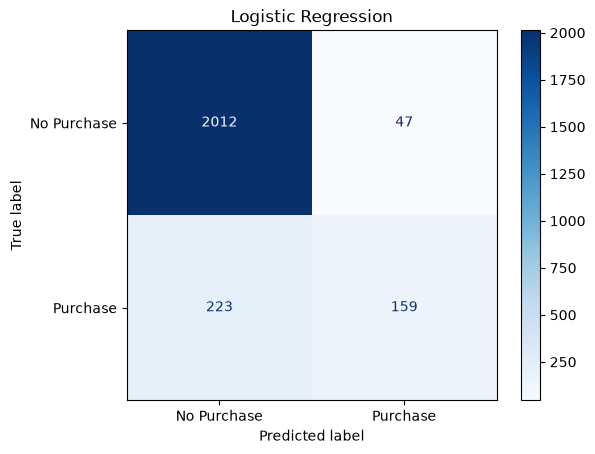

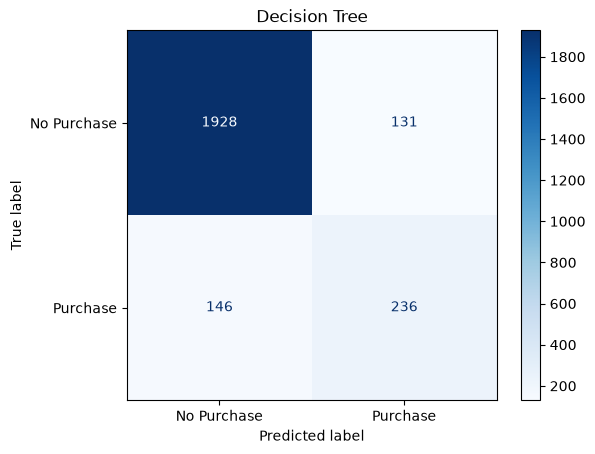

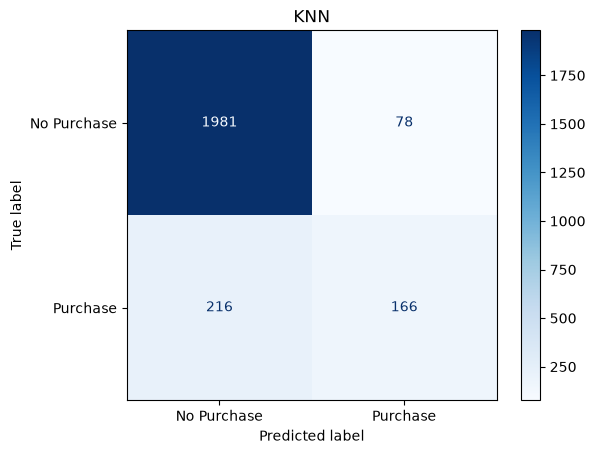

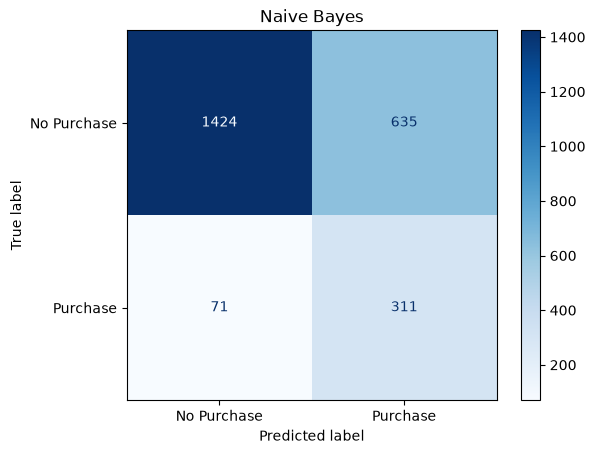

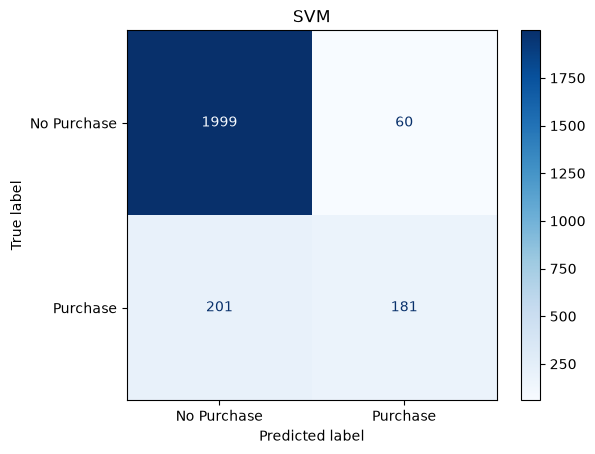

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Store predictions from all five models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "KNN": y_pred_knn,
    "Naive Bayes": y_pred_nb,
    "SVM": y_pred_svm
}

# Display confusion matrices
for model_name, predictions in model_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Purchase", "Purchase"]
    )

    display.plot(cmap="Blues")
    plt.title(model_name)
    plt.show()

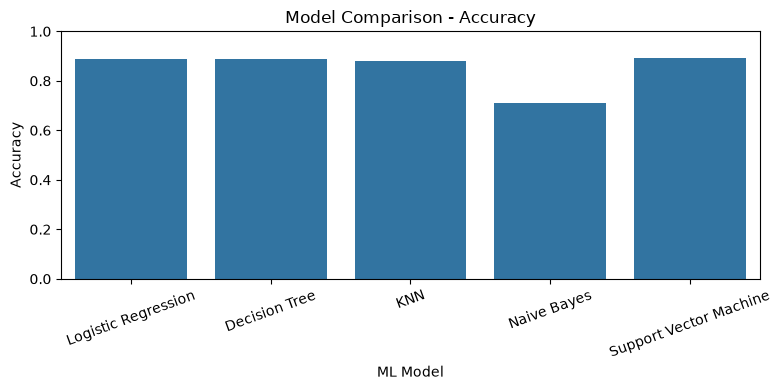

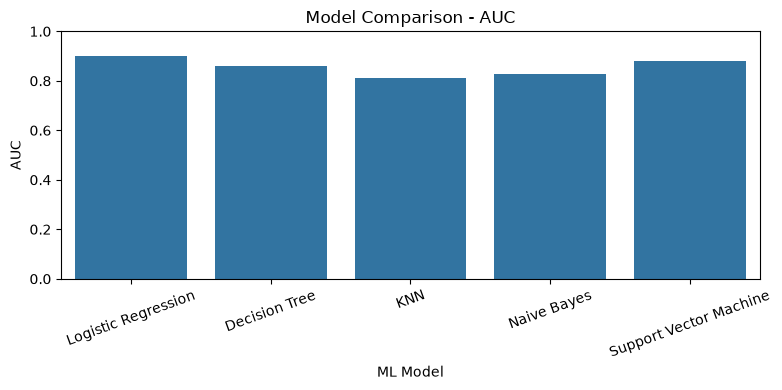

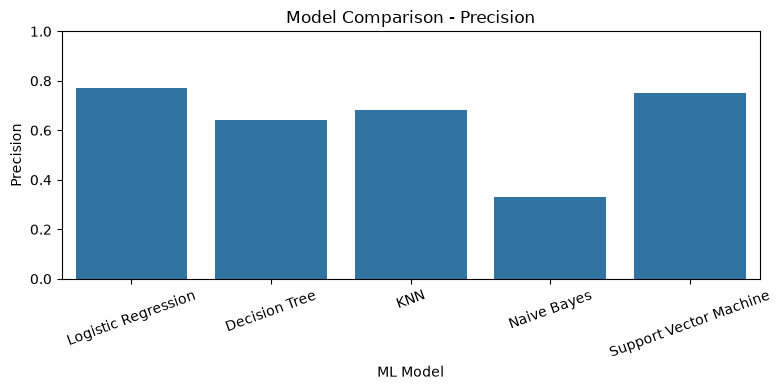

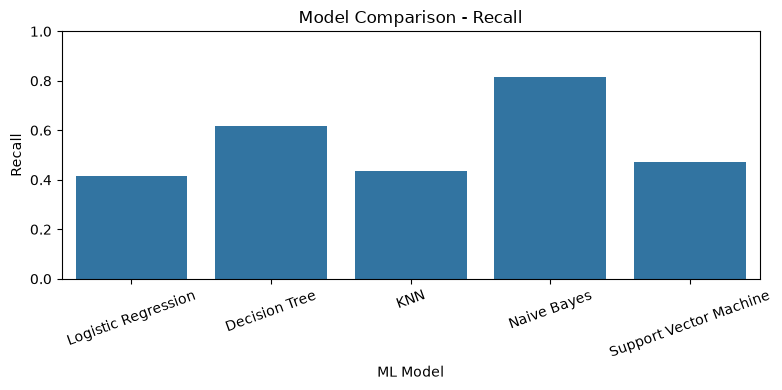

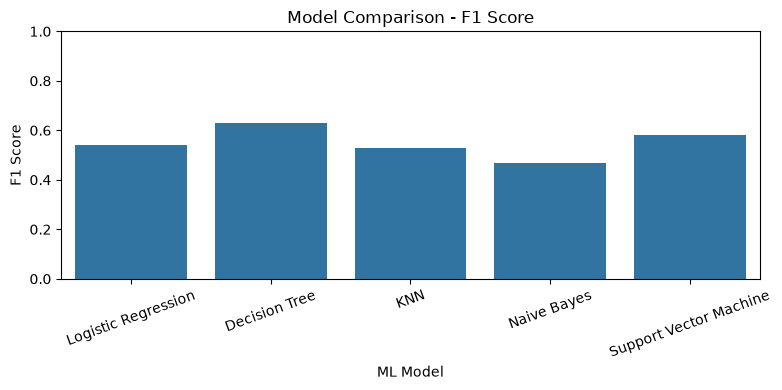

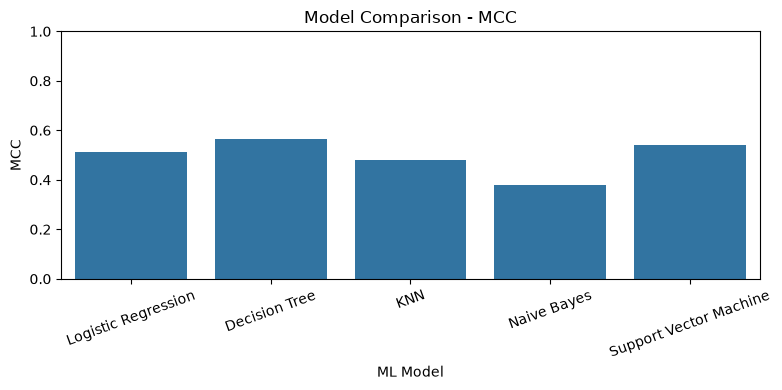

In [40]:
metrics = ["Accuracy", "AUC", "Precision", "Recall", "F1 Score", "MCC"]

for metric in metrics:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=comparison, x="ML Model", y=metric)
    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=20)
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

In [41]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    for file in files:
        if file.endswith(".joblib") or file.endswith(".csv"):
            print(os.path.join(root, file))

.\online_shoppers_intention.csv
.\test_data.csv
.\model\decision_tree.joblib
.\model\knn.joblib
.\model\logistic_regression.joblib
.\model\naive_bayes.joblib
.\model\preprocessing.joblib
.\model\svm.joblib
.\results\model_comparison.csv


In [42]:
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.0
